# My details :
*   Name : Tushar Kaldate
*   Roll : 47
*   Batch : A2
* PRN : 202401040191

# GitHub Repo : https://github.com/tusharkkp/AI-ML/

# **AI-ML Lab Practical No. 2:**


# [1] Title
## Performance Evaluation of Uninformed, Informed, Local, Adversarial and Constraint-Satisfaction Search Algorithms on an **Autonomous Amazon Warehouse Robot**

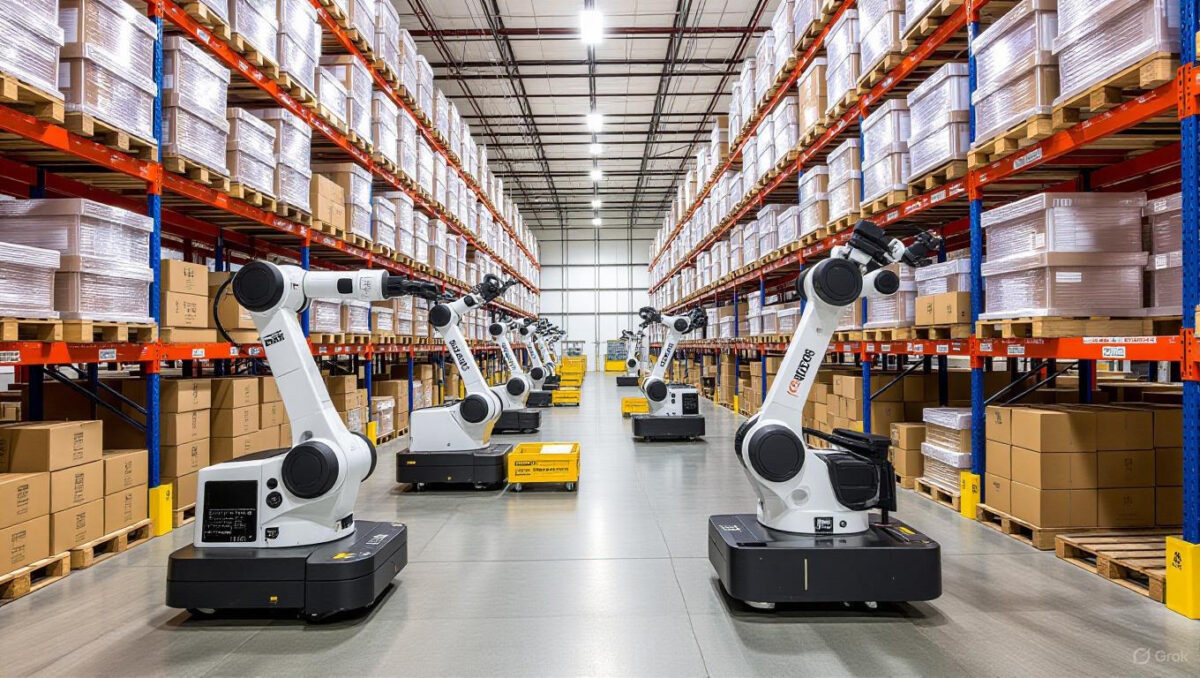

# [2] Aim
To model an **Autonomous Amazon Warehouse Robot** as a search problem and to **implement, run and compare** search / problem-solving techniques – Uninformed, Informed, Local Search, Adversarial Search and Constraint Satisfaction (CSP) – on the same warehouse instance, evaluating them on **completeness, optimality, time, space (nodes in memory) and nodes expanded**.

# [3] Experiment Objectives
1. Formulate the warehouse robot task as a well-defined search problem (state space, initial state, actions, transition model, goal test, path cost).
2. Implement **uninformed** strategies – BFS, Uniform-Cost, DFS, Depth-Limited, IDDFS, Bidirectional – for *point-to-point navigation*.
3. Implement **informed** strategies – Best-First, Greedy Best-First and A\* – using the Manhattan-distance heuristic.
4. Apply **local search** – Hill-Climbing and Genetic Algorithm – to the *multi-item pick-route optimisation* (TSP-like) problem.
5. Apply **adversarial search** – Minimax and Alpha-Beta pruning – to a *two-robot competitive item-collection game*.
6. Apply **CSP techniques** – Backtracking, MRV, Degree heuristic, LCV and Forward Checking – to the *robot traffic-slot scheduling* problem.
7. Compare the algorithms quantitatively (tables + charts) and draw conclusions on when each one should be used.

# [4] Experiment Outcomes
After completing this experiment the I will be able to:

* **1** – Formulate real-world problems (robot navigation, routing, scheduling, games) as search problems.
* **2** – Implement and differentiate uninformed vs. informed search and justify heuristic design (admissibility / consistency).
* **3** – Use local search (Hill-Climbing, GA) for optimisation problems where the path is irrelevant and the goal is a good configuration.
* **4** – Apply Minimax and Alpha-Beta pruning to decision making against an opponent.
* **5** – Solve CSPs using backtracking with variable/value-ordering heuristics and inference (forward checking).
* **6** – Evaluate algorithms empirically using nodes expanded, memory, path cost and run-time.

# [5] Conceptual Details

## 1. The case study – Autonomous Amazon Warehouse Robot
An Amazon fulfilment-centre drive unit moves on a grid floor. **Shelves (`#`) are obstacles**, **aisles (`.`) cost 1** to enter and **congested aisles (`~`) cost 5** (busy zones where many robots slow each other down). The robot starts at the charging dock **S** and must reach the packing station **G**.

The same warehouse is reused for every family of algorithms, each solving a *different sub-problem* that a real robot faces:


| Family | Warehouse sub-problem | Algorithms |
|---|---|---|
| Uninformed | Shortest route from dock **S** to packing station **G** with no domain knowledge | BFS, UCS, DFS, DLS, IDDFS, Bidirectional |
| Informed | Same route, using a Manhattan-distance heuristic | Best-First, Greedy, A\* |
| Local search | Best **order** in which to visit 8 pick locations and return to dock (TSP-like) | Hill-Climbing, Genetic Algorithm |
| Adversarial | Two robots compete for valuable items in a small zone | Minimax, Alpha-Beta |
| CSP | Assign 14 robots to 4 time-slots for a shared choke-point so conflicting robots never share a slot | Backtracking, MRV, Degree, LCV, Forward Checking |

## 2. Problem formulation (navigation)
* **State:** robot cell `(row, col)`
* **Initial state:** dock `S`  &nbsp;&nbsp; **Goal test:** state == `G`
* **Actions:** Up, Right, Down, Left (only into non-shelf cells inside the grid)
* **Transition model:** move to the neighbouring cell
* **Path cost:** sum of cell-entry costs (aisle = 1, congested = 5)
* **Heuristic:** Manhattan distance to `G` (admissible & consistent because every step costs ≥ 1)

## 3. Performance measures
* **Completeness** – does it always find a solution if one exists?
* **Optimality** – is the solution found the cheapest?
* **Time** – nodes *expanded* (plus wall-clock time)
* **Space** – maximum number of nodes held in memory (frontier / stack / population)

## 4. Theoretical comparison ( *b* = branching factor, *d* = depth of shallowest goal, *m* = max depth, *l* = depth limit, *C\** = optimal cost, *ε* = min step cost )

| Algorithm | Complete | Optimal | Time | Space |
|---|---|---|---|---|
| BFS | Yes | Yes (unit cost) | O(b^d) | O(b^d) |
| Uniform-Cost | Yes | **Yes** | O(b^(1+⌊C\*/ε⌋)) | O(b^(1+⌊C\*/ε⌋)) |
| DFS | No (infinite/loops) | No | O(b^m) | **O(bm)** |
| Depth-Limited | No (if l < d) | No | O(b^l) | O(bl) |
| IDDFS | Yes | Yes (unit cost) | O(b^d) | O(bd) |
| Bidirectional | Yes | Yes (unit cost) | O(b^(d/2)) | O(b^(d/2)) |
| Best-First (f = w·g + h) | Yes (finite) | No (w<1) | depends on f | depends on f |
| Greedy Best-First | No (tree) / Yes (graph) | No | O(b^m) worst | O(b^m) worst |
| A\* | Yes | **Yes** (admissible h) | exponential, but far fewer nodes | O(b^d) |
| Hill-Climbing | No | No (local optima) | O(iterations × neighbours) | O(1) |
| Genetic Algorithm | Probabilistically | No guarantee | O(gens × pop) | O(pop) |
| Minimax | Yes (finite tree) | Yes (vs. optimal opp.) | O(b^m) | O(bm) |
| Alpha-Beta | Yes | Yes (same value as Minimax) | O(b^(m/2)) best-case | O(bm) |
| Backtracking (CSP) | Yes | – | O(d^n) worst | O(n) |
| + MRV / Degree / LCV / FC | Yes | – | far fewer backtracks in practice | O(n·d) |

## 5. Brief description of every algorithm
**Uninformed search** (no knowledge about the goal location)
1. **BFS** – expands the shallowest node first (FIFO queue). Minimises *number of steps*, ignores cell costs.
2. **Uniform-Cost Search** – expands the node with the lowest path cost g(n) (priority queue). Optimal for arbitrary positive costs.
3. **DFS** – expands the deepest node first (LIFO stack). Low memory but can return very long, non-optimal paths.
4. **Depth-Limited Search** – DFS with a depth cut-off *l*; returns *cutoff* if the goal is deeper than *l*.
5. **IDDFS** – repeatedly runs DLS with l = 0, 1, 2, … – combines BFS optimality/completeness with DFS memory.
6. **Bidirectional Search** – two simultaneous BFS searches (from S and from G) that meet in the middle.

**Informed search** (uses heuristic h(n))

7. **Best-First Search** – general framework: always expand the node with the lowest evaluation function f(n). Here f(n) = 0.5·g(n) + h(n) (weighted).

8. **Greedy Best-First** – f(n) = h(n): rushes towards the goal, fast but not optimal.

9. **A\*** – f(n) = g(n) + h(n): complete and optimal with an admissible heuristic.

**Local search** (state = a complete solution; move to better neighbours)

10. **Hill-Climbing** – steepest-ascent on the pick-order permutation with swap moves; may get stuck in local optima (random restarts help).

11. **Genetic Algorithm** – population of pick orders evolved with selection, order-crossover, mutation and elitism.

**Adversarial search** (two players)

12. **Minimax** – MAX robot picks the move maximising the value assuming MIN plays optimally.

13. **Alpha-Beta Pruning** – Minimax that skips branches that cannot influence the decision.

**Constraint Satisfaction Problems**

14. **Backtracking Search** – DFS that assigns one variable at a time and undoes on conflict.

15. **MRV** – choose the variable with the *fewest legal values* (fail-first).

16. **Degree heuristic (most constraining variable)** – choose the variable involved in the most constraints with unassigned variables.

17. **LCV** – try the value that *rules out the fewest* values of the neighbours first.

18. **Forward Checking** – after each assignment delete inconsistent values from neighbours' domains; back up immediately if a domain becomes empty.


# [6] Algorithm / Flowchart

## a. BFS

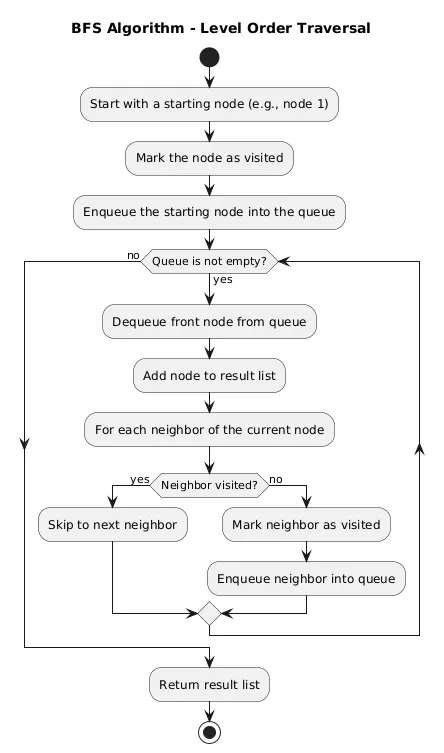

## b. Genetics :
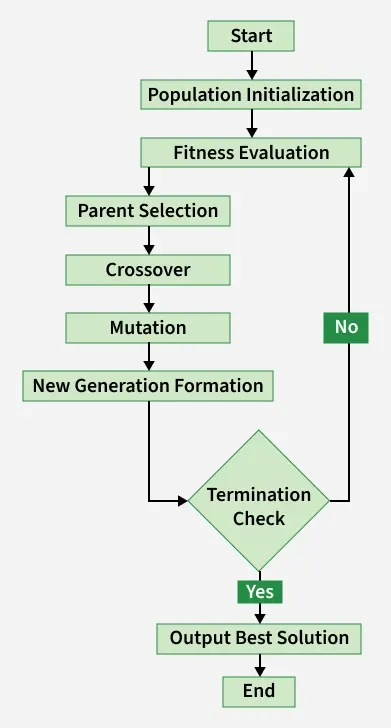


## B. Pseudocode of the important algorithms
```
UNIFORM-COST(S, G):                     A*(S, G):
  PQ <- {(0, S)}; g[S] <- 0                PQ <- {(h(S), S)}; g[S] <- 0
  while PQ not empty:                      while PQ not empty:
     (c, n) <- pop min                        (f, n) <- pop min f = g+h
     if n == G: return path                   if n == G: return path
     for m in neighbours(n):                  for m in neighbours(n):
        c2 <- g[n] + cost(m)                     c2 <- g[n] + cost(m)
        if c2 < g[m]: g[m]<-c2; push(c2,m)       if c2 < g[m]: g[m]<-c2; push(c2+h(m), m)

IDDFS(S, G):                            BIDIRECTIONAL(S, G):
  for l = 0,1,2,...:                       QF <- {S}; QB <- {G}
     r <- DLS(S, G, l)                     repeat: expand one level of the smaller queue
     if r != cutoff: return r                 if a generated node is known to the other side -> join paths
```
```
HILL-CLIMBING(order):                    GENETIC-ALGORITHM:
  current <- random permutation            P <- random population of pick orders
  loop:                                    repeat for G generations:
     best <- best swap-neighbour of current     evaluate fitness = 1 / tour-cost
     if cost(best) >= cost(current):            keep elite; choose parents by tournament
         return current      # local optimum     child <- ORDER-CROSSOVER(p1,p2); mutate (swap)
     current <- best                        return best individual
```
```
MINIMAX(s, d):                           ALPHA-BETA(s, d, α, β):
  if terminal or d==0: return eval(s)       if terminal or d==0: return eval(s)
  if MAX: return max MINIMAX(child, d-1)    if MAX: v=-∞; for child: v=max(v,AB(child,d-1,α,β));
  if MIN: return min MINIMAX(child, d-1)              α=max(α,v); if α>=β: break   # prune
                                            if MIN: v=+∞; for child: v=min(v,AB(...)); β=min(β,v); if α>=β: break
```
```
BACKTRACK(assignment, domains):
  if assignment complete: return assignment
  var <- SELECT-VARIABLE   (static order | MRV | Degree)
  for val in ORDER-VALUES(var)   (static order | LCV):
      if val consistent with assignment:
          assign var=val;   [Forward checking: remove val from neighbours' domains; fail if a domain is empty]
          result <- BACKTRACK(...)
          if result != failure: return result
          undo assignment (restore domains)
  return failure
```

# [7] Python Code
The code is divided into 6 parts:

**(0)** setup & environment,

**(1)** uninformed search,

**(2)** informed search,

**(3)** local search,

**(4)** adversarial search,

**(5)** constraint satisfaction.

## Part 0 – Setup and the Warehouse Environment

In [ ]:
import heapq, time, random, itertools, math
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [ ]:
# Warehouse layout:  S = charging dock (start)   G = packing station (goal)
#                    # = shelf (obstacle)         . = aisle (cost 1)     ~ = congested aisle (cost 5)
WAREHOUSE = [
    "S..~~~.~..",
    "~##.##.##~",
    "~##.##.##.",
    "....~...~~",
    "~##.##.##~",
    "~##.##.##~",
    "..~..~...~",
    "~##.##.##~",
    ".##.##.##~",
    ".~.......G",
]
# (the short, direct aisles are congested, so the cheapest route is a detour - this separates step-count from cost)

class Warehouse:
    MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]          # Up, Right, Down, Left
    NAMES = ["U", "R", "D", "L"]

    def __init__(self, layout):
        self.grid = [list(r) for r in layout]
        self.R, self.C = len(layout), len(layout[0])
        for r in range(self.R):
            for c in range(self.C):
                if self.grid[r][c] == "S": self.start = (r, c)
                if self.grid[r][c] == "G": self.goal = (r, c)

    def passable(self, s):
        r, c = s
        return 0 <= r < self.R and 0 <= c < self.C and self.grid[r][c] != "#"

    def step_cost(self, s):                              # cost of ENTERING cell s
        return 5 if self.grid[s[0]][s[1]] == "~" else 1

    def neighbors(self, s):
        return [(s[0] + dr, s[1] + dc) for dr, dc in self.MOVES if self.passable((s[0] + dr, s[1] + dc))]

    def path_cost(self, path):
        return sum(self.step_cost(p) for p in path[1:]) if path else None

env = Warehouse(WAREHOUSE)
START, GOAL = env.start, env.goal

def manhattan(a, b=None):
    b = b or GOAL
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def build_path(parent, node):
    path = []
    while node is not None:
        path.append(node); node = parent[node]
    return path[::-1]

print("Start:", START, " Goal:", GOAL, " Grid:", env.R, "x", env.C)
print("Free cells:", sum(env.passable((r, c)) for r in range(env.R) for c in range(env.C)))

Start: (0, 0)  Goal: (9, 9)  Grid: 10 x 10
Free cells: 64


## Part 1 – Uninformed Search (Algorithms 1 – 6)
Every function returns `(path, nodes_expanded, peak_nodes_in_memory)`.

In [ ]:
# 1. BREADTH-FIRST SEARCH
def bfs(env, start, goal):
    frontier, parent = deque([start]), {start: None}
    expanded, peak = 0, 1
    if start == goal: return [start], 0, 1
    while frontier:
        s = frontier.popleft(); expanded += 1
        for n in env.neighbors(s):
            if n not in parent:
                parent[n] = s
                if n == goal: return build_path(parent, n), expanded, peak
                frontier.append(n)
        peak = max(peak, len(frontier))
    return None, expanded, peak

# 2. UNIFORM-COST SEARCH
def ucs(env, start, goal):
    pq, g, parent, closed = [(0, 0, start)], {start: 0}, {start: None}, set()
    cnt, expanded, peak = 1, 0, 1
    while pq:
        peak = max(peak, len(pq))
        c, _, s = heapq.heappop(pq)
        if s in closed: continue
        closed.add(s); expanded += 1
        if s == goal: return build_path(parent, s), expanded, peak
        for n in env.neighbors(s):
            nc = c + env.step_cost(n)
            if nc < g.get(n, float("inf")):
                g[n], parent[n] = nc, s
                heapq.heappush(pq, (nc, cnt, n)); cnt += 1
    return None, expanded, peak

# 3. DEPTH-FIRST SEARCH  (graph search with an explored set so it cannot loop)
def dfs(env, start, goal):
    stack, parent = [(start, None)], {}
    expanded, peak = 0, 1
    while stack:
        peak = max(peak, len(stack))
        s, p = stack.pop()
        if s in parent: continue
        parent[s] = p; expanded += 1
        if s == goal: return build_path(parent, s), expanded, peak
        for n in reversed(env.neighbors(s)):
            if n not in parent: stack.append((n, s))
    return None, expanded, peak

# 4. DEPTH-LIMITED SEARCH  (returns path, or "cutoff", or None for failure)
def dls(env, start, goal, limit):
    stats = {"exp": 0, "peak": 0}
    best_depth = {}                                # avoids re-exploring a state reached at an equal/greater depth
    def rec(s, depth, path):
        stats["exp"] += 1; stats["peak"] = max(stats["peak"], depth + 1)
        if s == goal: return list(path)
        if depth == limit: return "cutoff"
        best_depth[s] = depth
        cutoff = False
        for n in env.neighbors(s):
            if n in path: continue                 # no cycle along the current path
            if best_depth.get(n, 10**9) <= depth + 1: continue
            path.append(n)
            r = rec(n, depth + 1, path)
            path.pop()
            if r == "cutoff": cutoff = True
            elif r is not None: return r
        return "cutoff" if cutoff else None
    res = rec(start, 0, [start])
    return res, stats["exp"], stats["peak"]

def dls_wrapper(env, start, goal, limit=25):
    res, e, p = dls(env, start, goal, limit)
    return (res if isinstance(res, list) else None), e, p

# 5. ITERATIVE-DEEPENING DFS
def iddfs(env, start, goal, max_depth=60):
    total_exp, peak = 0, 0
    for limit in range(max_depth + 1):
        res, e, p = dls(env, start, goal, limit)
        total_exp += e; peak = max(peak, p)
        if res != "cutoff":
            return (res if isinstance(res, list) else None), total_exp, peak
    return None, total_exp, peak

# 6. BIDIRECTIONAL SEARCH  (two BFS waves, from S and from G, meet in the middle)
def bidirectional(env, start, goal):
    if start == goal: return [start], 0, 1
    pf, pb = {start: None}, {goal: None}
    qf, qb = deque([start]), deque([goal])
    expanded, peak = 0, 2
    def join(meet):
        a = build_path(pf, meet)                   # S ... meet
        b = build_path(pb, meet)[::-1]             # meet ... G
        return a + b[1:]
    while qf and qb:
        # expand one full level of the smaller frontier
        forward = len(qf) <= len(qb)
        q, mine, other = (qf, pf, pb) if forward else (qb, pb, pf)
        for _ in range(len(q)):
            s = q.popleft(); expanded += 1
            for n in env.neighbors(s):
                if n not in mine:
                    mine[n] = s
                    if n in other: return join(n), expanded, peak
                    q.append(n)
        peak = max(peak, len(qf) + len(qb))
    return None, expanded, peak

In [ ]:
def print_route(name, result):
    route, expanded, peak = result

    print(f"\n{name}")
    if route is None:
        print("Route: No route found")
    else:
        print("Route:", " -> ".join(map(str, route)))
        print("Steps:", len(route) - 1)

    print("Expanded:", expanded)
    print("Peak frontier:", peak)

In [ ]:
start = env.start
goal = env.goal

print_route("BFS", bfs(env, start, goal))

print_route("UCS", ucs(env, start, goal))

print_route("DFS", dfs(env, start, goal))

print_route("DLS", dls_wrapper(env, start, goal, limit=25))

print_route("IDDFS", iddfs(env, start, goal, max_depth=60))

print_route("Bidirectional BFS", bidirectional(env, start, goal))


BFS
Route: (0, 0) -> (0, 1) -> (0, 2) -> (0, 3) -> (0, 4) -> (0, 5) -> (0, 6) -> (0, 7) -> (0, 8) -> (0, 9) -> (1, 9) -> (2, 9) -> (3, 9) -> (4, 9) -> (5, 9) -> (6, 9) -> (7, 9) -> (8, 9) -> (9, 9)
Steps: 18
Expanded: 62
Peak frontier: 6

UCS
Route: (0, 0) -> (0, 1) -> (0, 2) -> (0, 3) -> (1, 3) -> (2, 3) -> (3, 3) -> (4, 3) -> (5, 3) -> (6, 3) -> (7, 3) -> (8, 3) -> (9, 3) -> (9, 4) -> (9, 5) -> (9, 6) -> (9, 7) -> (9, 8) -> (9, 9)
Steps: 18
Expanded: 49
Peak frontier: 10

DFS
Route: (0, 0) -> (0, 1) -> (0, 2) -> (0, 3) -> (0, 4) -> (0, 5) -> (0, 6) -> (0, 7) -> (0, 8) -> (0, 9) -> (1, 9) -> (2, 9) -> (3, 9) -> (4, 9) -> (5, 9) -> (6, 9) -> (7, 9) -> (8, 9) -> (9, 9)
Steps: 18
Expanded: 19
Peak frontier: 6

DLS
Route: (0, 0) -> (0, 1) -> (0, 2) -> (0, 3) -> (0, 4) -> (0, 5) -> (0, 6) -> (0, 7) -> (0, 8) -> (0, 9) -> (1, 9) -> (2, 9) -> (3, 9) -> (4, 9) -> (5, 9) -> (6, 9) -> (7, 9) -> (8, 9) -> (9, 9)
Steps: 18
Expanded: 19
Peak frontier: 19

IDDFS
Route: (0, 0) -> (0, 1) -> (0, 2) -

## Part 2 – Informed Search (Algorithms 7 – 9)
All three are one generic *best-first* routine that only differs in the **evaluation function** `f(g, h)`.

In [ ]:
# 7-9. BEST-FIRST FAMILY  (generic: always expand the node with the smallest f)
def best_first(env, start, goal, f, h=manhattan):
    pq, g, parent, closed = [(f(0, h(start)), h(start), 0, start)], {start: 0}, {start: None}, set()
    cnt, expanded, peak = 1, 0, 1
    while pq:
        peak = max(peak, len(pq))
        _, _, _, s = heapq.heappop(pq)
        if s in closed: continue
        closed.add(s); expanded += 1
        if s == goal: return build_path(parent, s), expanded, peak
        for n in env.neighbors(s):
            ng = g[s] + env.step_cost(n)
            if ng < g.get(n, float("inf")):
                g[n], parent[n] = ng, s
                heapq.heappush(pq, (f(ng, h(n)), h(n), cnt, n)); cnt += 1
    return None, expanded, peak

def best_first_search(env, s, g_):  return best_first(env, s, g_, lambda g, h: 0.5 * g + h)   # 7. weighted best-first
def greedy_best_first(env, s, g_):  return best_first(env, s, g_, lambda g, h: h)              # 8. Greedy
def a_star(env, s, g_):             return best_first(env, s, g_, lambda g, h: g + h)          # 9. A*

In [ ]:
# Define start and goal first
start = env.start
goal = env.goal


# 7-9
print_route("Weighted Best-First Search", best_first_search(env, start, goal))
print_route("Greedy Best-First Search", greedy_best_first(env, start, goal))
print_route("A* Search", a_star(env, start, goal))


Weighted Best-First Search
Route: (0, 0) -> (0, 1) -> (0, 2) -> (0, 3) -> (1, 3) -> (2, 3) -> (3, 3) -> (4, 3) -> (5, 3) -> (6, 3) -> (7, 3) -> (8, 3) -> (9, 3) -> (9, 4) -> (9, 5) -> (9, 6) -> (9, 7) -> (9, 8) -> (9, 9)
Steps: 18
Expanded: 20
Peak frontier: 9

Greedy Best-First Search
Route: (0, 0) -> (0, 1) -> (0, 2) -> (0, 3) -> (0, 4) -> (0, 5) -> (0, 6) -> (0, 7) -> (0, 8) -> (0, 9) -> (1, 9) -> (2, 9) -> (3, 9) -> (4, 9) -> (5, 9) -> (6, 9) -> (7, 9) -> (8, 9) -> (9, 9)
Steps: 18
Expanded: 19
Peak frontier: 6

A* Search
Route: (0, 0) -> (0, 1) -> (0, 2) -> (0, 3) -> (1, 3) -> (2, 3) -> (3, 3) -> (4, 3) -> (5, 3) -> (6, 3) -> (7, 3) -> (8, 3) -> (9, 3) -> (9, 4) -> (9, 5) -> (9, 6) -> (9, 7) -> (9, 8) -> (9, 9)
Steps: 18
Expanded: 20
Peak frontier: 9


### Run and compare all navigation algorithms (Uninformed + Informed)

In [ ]:
def run_nav(name, fn, repeats=20):
    t0 = time.perf_counter()
    for _ in range(repeats): out = fn(env, START, GOAL)
    ms = (time.perf_counter() - t0) / repeats * 1000
    path, expanded, peak = out
    return {"Algorithm": name, "Found": path is not None,
            "Steps": len(path) - 1 if path else None,
            "Path cost": env.path_cost(path) if path else None,
            "Nodes expanded": expanded, "Peak memory (nodes)": peak,
            "Time (ms)": round(ms, 3)}, path

NAV_ALGOS = [
    ("1. BFS", bfs), ("2. Uniform-Cost", ucs), ("3. DFS", dfs),
    ("4. Depth-Limited (l=25)", lambda e, s, g: dls_wrapper(e, s, g, 25)),
    ("5. IDDFS", iddfs), ("6. Bidirectional", bidirectional),
    ("7. Best-First (0.5g+h)", best_first_search), ("8. Greedy Best-First", greedy_best_first), ("9. A*", a_star),
]
rows, paths = [], {}
for name, fn in NAV_ALGOS:
    r, p = run_nav(name, fn); rows.append(r); paths[name] = p
nav_df = pd.DataFrame(rows)
opt = nav_df.loc[nav_df["Algorithm"] == "2. Uniform-Cost", "Path cost"].iloc[0]
nav_df["Optimal?"] = nav_df["Path cost"] == opt
display(nav_df)

# Depth-limited search: too small a limit -> cutoff (incomplete)
for L in (10, 15, 18, 25):
    res, e, p = dls(env, START, GOAL, L)
    print(f"DLS limit={L:>2}: ", "CUTOFF (goal deeper than limit)" if res == "cutoff" else f"path found, {len(res)-1} steps", f"| expanded={e}")

,Algorithm,Found,Steps,Path cost,Nodes expanded,Peak memory (nodes),Time (ms),Optimal?
0,1. BFS,True,18,62,62,6,0.125,False
1,2. Uniform-Cost,True,18,22,49,10,0.361,True
2,3. DFS,True,18,62,19,6,0.091,False
3,4. Depth-Limited (l=25),True,18,62,19,19,0.109,False
4,5. IDDFS,True,18,62,826,19,2.704,False
5,6. Bidirectional,True,18,62,53,12,0.134,False
6,7. Best-First (0.5g+h),True,18,22,20,9,0.108,True
7,8. Greedy Best-First,True,18,62,19,6,0.086,False
8,9. A*,True,18,22,20,9,0.102,True


DLS limit=10:  CUTOFF (goal deeper than limit) | expanded=47
DLS limit=15:  CUTOFF (goal deeper than limit) | expanded=97
DLS limit=18:  path found, 18 steps | expanded=19
DLS limit=25:  path found, 18 steps | expanded=19


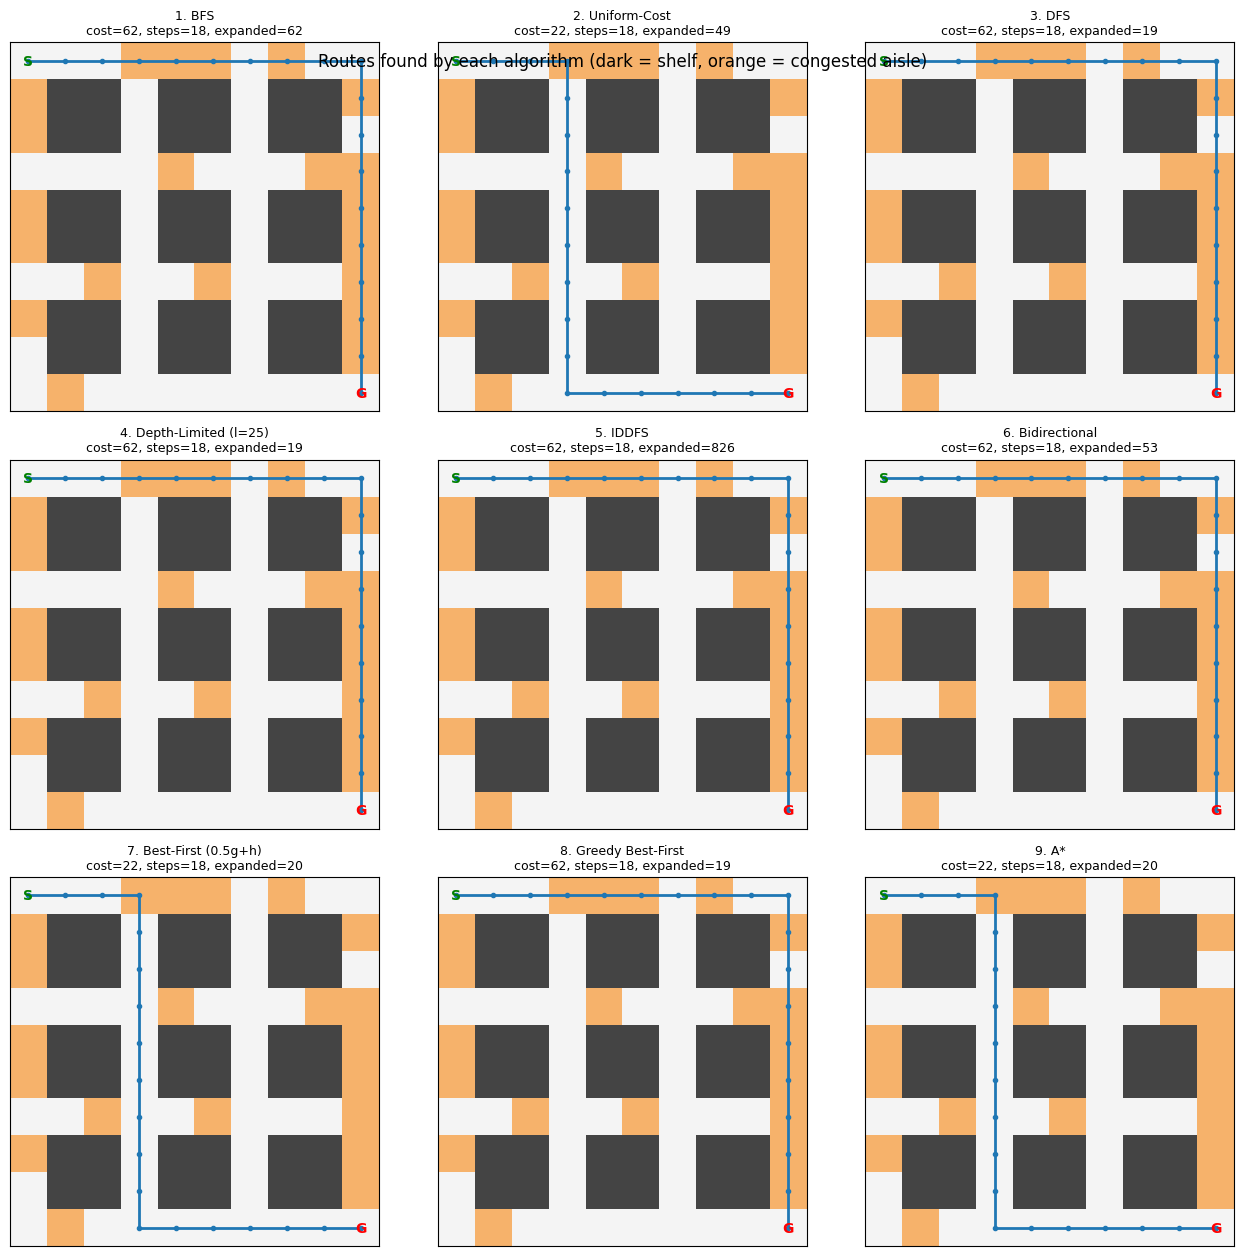

In [ ]:
# Visualise the route found by every navigation algorithm
def draw(ax, path, title):
    img = np.zeros((env.R, env.C))
    for r in range(env.R):
        for c in range(env.C):
            ch = env.grid[r][c]
            img[r, c] = {"#": 0, ".": 1, "~": 2, "S": 1, "G": 1}[ch]
    ax.imshow(img, cmap=plt.matplotlib.colors.ListedColormap(["#444444", "#f4f4f4", "#f6b26b"]), vmin=0, vmax=2)
    if path:
        ys, xs = zip(*path); ax.plot(xs, ys, "-o", color="#1f77b4", ms=3, lw=2)
    ax.text(START[1], START[0], "S", ha="center", va="center", color="green", fontweight="bold")
    ax.text(GOAL[1], GOAL[0], "G", ha="center", va="center", color="red", fontweight="bold")
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for ax, (name, _) in zip(axes.ravel(), NAV_ALGOS):
    row = nav_df[nav_df["Algorithm"] == name].iloc[0]
    draw(ax, paths[name], f"{name}\ncost={row['Path cost']}, steps={row['Steps']}, expanded={row['Nodes expanded']}")
plt.suptitle("Routes found by each algorithm (dark = shelf, orange = congested aisle)", y=0.93)
plt.tight_layout(); plt.show()

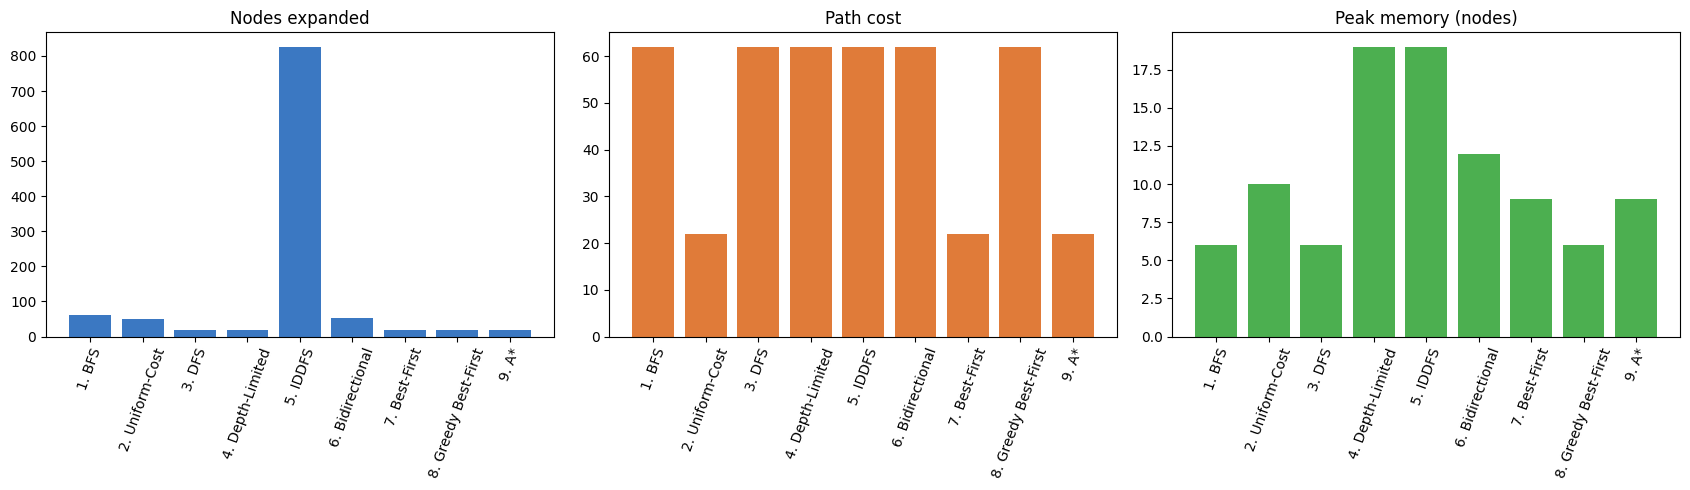

In [ ]:
# Bar charts: nodes expanded, path cost, memory
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
short = [n.split(". ")[0] + ". " + n.split(". ")[1].split(" (")[0] for n in nav_df["Algorithm"]]
for a, col, colr in zip(ax, ["Nodes expanded", "Path cost", "Peak memory (nodes)"], ["#3b78c2", "#e07b39", "#4caf50"]):
    a.bar(short, nav_df[col], color=colr); a.set_title(col); a.tick_params(axis="x", rotation=70)
plt.tight_layout(); plt.show()

## Part 3 – Local Search (Algorithms 10 – 11)
**Sub-problem:** the robot must collect **8 items** at given shelf-front cells and return to the dock. Which **visiting order** minimises the total travelled cost? The *path* is irrelevant – only the final *order* (a permutation) matters, which is exactly the setting for local search.
Pair-wise travel costs are pre-computed with Dijkstra (uniform-cost search from every pick location).

In [ ]:
PICKS = [(0, 6), (1, 3), (3, 8), (4, 6), (6, 2), (6, 9), (9, 4), (8, 0)]        # 8 items to pick
for p in PICKS: assert env.passable(p) and p != START

def dijkstra_all(env, src):
    dist, pq = {src: 0}, [(0, src)]
    while pq:
        d, s = heapq.heappop(pq)
        if d > dist[s]: continue
        for n in env.neighbors(s):
            nd = d + env.step_cost(n)
            if nd < dist.get(n, 1e9): dist[n] = nd; heapq.heappush(pq, (nd, n))
    return dist

nodes = [START] + PICKS                                    # index 0 = dock, 1..8 = pick locations
D = np.array([[dijkstra_all(env, a)[b] for b in nodes] for a in nodes])
N = len(PICKS)

def tour_cost(order):                                      # dock -> picks in 'order' -> dock
    seq = [0] + list(order) + [0]
    return int(sum(D[seq[i], seq[i + 1]] for i in range(len(seq) - 1)))

# Ground truth by brute force (8! = 40 320 permutations) so we can measure the quality of the heuristics
t0 = time.perf_counter()
best_perm = min(itertools.permutations(range(1, N + 1)), key=tour_cost)
OPT_COST = tour_cost(best_perm)
print(f"Brute-force optimum = {OPT_COST}  order = {best_perm}   (took {time.perf_counter()-t0:.2f}s, 40 320 evaluations)")

Brute-force optimum = 82  order = (1, 3, 4, 6, 7, 8, 5, 2)   (took 0.13s, 40 320 evaluations)


In [ ]:
# 10. HILL-CLIMBING (steepest-ascent, swap neighbourhood, optional random restarts)
def hill_climbing(seed=0, restarts=1):
    rng = random.Random(seed)
    best, best_cost, evals, history = None, float("inf"), 0, []
    for _ in range(restarts):
        cur = list(range(1, N + 1)); rng.shuffle(cur); cur_cost = tour_cost(cur); evals += 1
        while True:
            cand, cand_cost = None, cur_cost
            for i, j in itertools.combinations(range(N), 2):          # all swap neighbours
                nb = cur[:]; nb[i], nb[j] = nb[j], nb[i]
                c = tour_cost(nb); evals += 1
                if c < cand_cost: cand, cand_cost = nb, c
            if cand is None: break                                     # local optimum reached
            cur, cur_cost = cand, cand_cost; history.append(cur_cost)
        if cur_cost < best_cost: best, best_cost = cur, cur_cost
    return best, best_cost, evals, history



In [ ]:
optimal_route = [nodes[i] for i in [0] + list(best_perm) + [0]]

print("\nOptimal Route:")
print(" -> ".join(map(str, optimal_route)))
print(f"Total Cost = {OPT_COST}")


Optimal Route:
(0, 0) -> (0, 6) -> (3, 8) -> (4, 6) -> (6, 9) -> (9, 4) -> (8, 0) -> (6, 2) -> (1, 3) -> (0, 0)
Total Cost = 82


In [ ]:
# 11. GENETIC ALGORITHM (permutation encoding, tournament selection, order crossover, swap mutation, elitism)
def order_crossover(p1, p2, rng):
    a, b = sorted(rng.sample(range(len(p1)), 2))
    child = [None] * len(p1); child[a:b + 1] = p1[a:b + 1]
    fill = [g for g in p2 if g not in child[a:b + 1]]
    it = iter(fill)
    return [g if g is not None else next(it) for g in child]

def genetic_algorithm(seed=0, pop_size=60, generations=150, pc=0.9, pm=0.25, elite=2, k=3):
    rng = random.Random(seed)
    pop = [rng.sample(range(1, N + 1), N) for _ in range(pop_size)]
    evals, history = 0, []
    for _ in range(generations):
        scored = sorted(pop, key=tour_cost); evals += len(pop)
        history.append(tour_cost(scored[0]))
        nxt = [s[:] for s in scored[:elite]]                            # elitism
        while len(nxt) < pop_size:
            p1 = min(rng.sample(pop, k), key=tour_cost); p2 = min(rng.sample(pop, k), key=tour_cost)
            child = order_crossover(p1, p2, rng) if rng.random() < pc else p1[:]
            if rng.random() < pm:
                i, j = rng.sample(range(N), 2); child[i], child[j] = child[j], child[i]
            nxt.append(child)
        pop = nxt
    best = min(pop, key=tour_cost)
    return best, tour_cost(best), evals, history

In [ ]:
# Run Genetic Algorithm
ga_perm, ga_cost, ga_evals, ga_history = genetic_algorithm(seed=0)

# Convert permutation indices to actual coordinates
ga_route = [nodes[i] for i in [0] + ga_perm + [0]]

print("\nGenetic Algorithm Route:")
print(" -> ".join(map(str, ga_route)))
print(f"Total Cost = {ga_cost}")


Genetic Algorithm Route:
(0, 0) -> (0, 6) -> (3, 8) -> (4, 6) -> (6, 9) -> (9, 4) -> (8, 0) -> (6, 2) -> (1, 3) -> (0, 0)
Total Cost = 82


In [ ]:
# Repeat each stochastic algorithm 30 times (different seeds) to measure reliability
TRIALS = 30
res = {"Hill-Climbing (1 run)": [], "Hill-Climbing (10 restarts)": [], "Genetic Algorithm": []}
for s in range(TRIALS):
    t0 = time.perf_counter(); _, c, e, _ = hill_climbing(s, 1);  res["Hill-Climbing (1 run)"].append((c, e, time.perf_counter() - t0))
    t0 = time.perf_counter(); _, c, e, _ = hill_climbing(s, 10); res["Hill-Climbing (10 restarts)"].append((c, e, time.perf_counter() - t0))
    t0 = time.perf_counter(); _, c, e, _ = genetic_algorithm(s); res["Genetic Algorithm"].append((c, e, time.perf_counter() - t0))

rows = []
for name, v in res.items():
    costs = np.array([x[0] for x in v])
    rows.append({"Algorithm": name, "Best cost": costs.min(), "Mean cost": round(costs.mean(), 1), "Worst cost": costs.max(),
                 "Runs hitting optimum": f"{(costs == OPT_COST).sum()}/{TRIALS}",
                 "Mean gap to optimum %": round((costs.mean() - OPT_COST) / OPT_COST * 100, 2),
                 "Avg evaluations": int(np.mean([x[1] for x in v])), "Avg time (ms)": round(np.mean([x[2] for x in v]) * 1000, 1)})
rows.append({"Algorithm": "Brute force (exact)", "Best cost": OPT_COST, "Mean cost": OPT_COST, "Worst cost": OPT_COST,
             "Runs hitting optimum": "always", "Mean gap to optimum %": 0.0, "Avg evaluations": math.factorial(N), "Avg time (ms)": "-"})
local_df = pd.DataFrame(rows); display(local_df)

,Algorithm,Best cost,Mean cost,Worst cost,Runs hitting optimum,Mean gap to optimum %,Avg evaluations,Avg time (ms)
0,Hill-Climbing (1 run),82,84.6,96,14/30,3.17,141,0.7
1,Hill-Climbing (10 restarts),82,82.0,82,30/30,0.00,1424,6.4
2,Genetic Algorithm,82,82.7,84,20/30,0.81,9000,356.5
3,Brute force (exact),82,82.0,82,always,0.00,40320,-


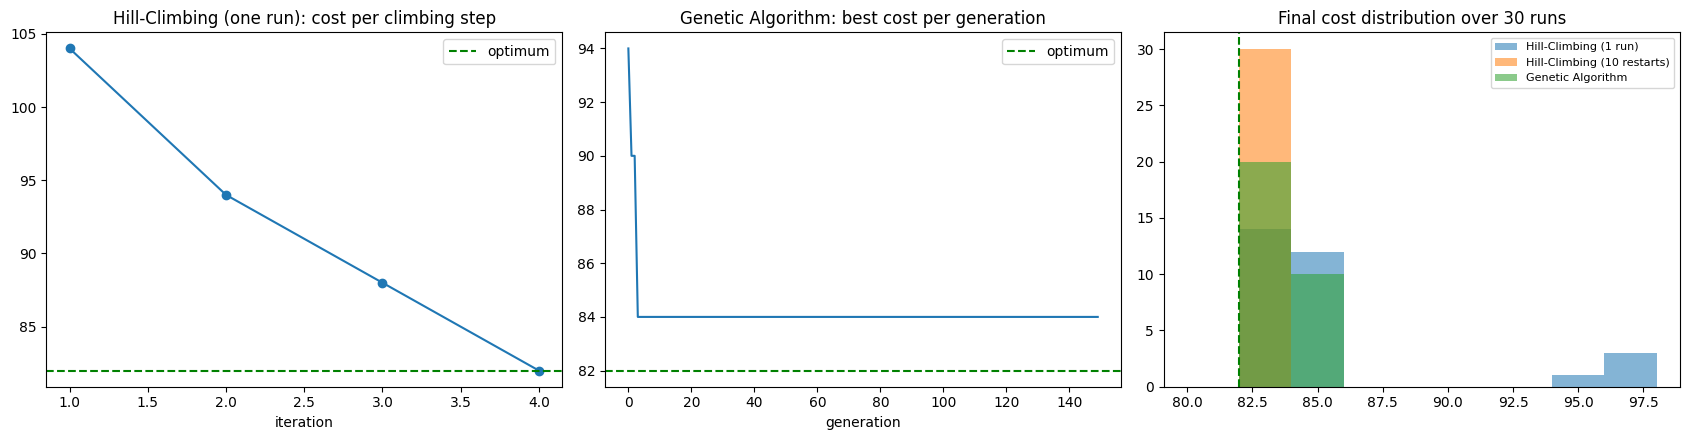

Best GA pick order (seed 0): ['Dock', 'P1(0, 6)', 'P3(3, 8)', 'P4(4, 6)', 'P6(6, 9)', 'P7(9, 4)', 'P8(8, 0)', 'P5(6, 2)', 'P2(1, 3)', 'Dock'] | cost = 82


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
_, _, _, h_hc = hill_climbing(3, 1); _, _, _, h_ga = genetic_algorithm(3)
ax[0].plot(range(1, len(h_hc) + 1), h_hc, "-o"); ax[0].axhline(OPT_COST, color="g", ls="--", label="optimum")
ax[0].set_title("Hill-Climbing (one run): cost per climbing step"); ax[0].set_xlabel("iteration"); ax[0].legend()
ax[1].plot(h_ga); ax[1].axhline(OPT_COST, color="g", ls="--", label="optimum")
ax[1].set_title("Genetic Algorithm: best cost per generation"); ax[1].set_xlabel("generation"); ax[1].legend()
for name, v in res.items(): ax[2].hist([x[0] for x in v], bins=range(OPT_COST - 2, max(x[0] for vv in res.values() for x in vv) + 4, 2), alpha=0.55, label=name)
ax[2].axvline(OPT_COST, color="g", ls="--"); ax[2].set_title(f"Final cost distribution over {TRIALS} runs"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

b, c, _, _ = genetic_algorithm(0)
print("Best GA pick order (seed 0):", ["Dock"] + [f"P{i}{PICKS[i-1]}" for i in b] + ["Dock"], "| cost =", c)

## Part 4 – Adversarial Search (Algorithms 14 – 15)
**Sub-problem:** two robots (**A** = our robot, MAX; **B** = a competitor, MIN) move on a small 5×5 zone and race to pick up valuable items. A robot gets the item's value when it steps on the item's cell. The **score difference (A − B)** is maximised by A and minimised by B. Robots move one cell per turn (4 directions) and cannot enter the other robot's cell.

In [ ]:
GAME_MAP = [
    "...#.",
    ".#...",
    "...#.",
    ".#...",
    ".....",
]
ITEMS = {(0, 4): 5, (4, 0): 5, (2, 2): 4, (1, 3): 2, (3, 2): 2}      # item cell -> value
GR, GC = 5, 5
def gfree(p): return 0 <= p[0] < GR and 0 <= p[1] < GC and GAME_MAP[p[0]][p[1]] != "#"

# state = (posA, posB, remaining_items(frozenset), score_diff, turn)  turn 0 = A (MAX), 1 = B (MIN)
INIT = ((0, 0), (4, 4), frozenset(ITEMS), 0, 0)

def moves(state):
    a, b, items, diff, turn = state
    me, other = (a, b) if turn == 0 else (b, a)
    out = []
    for dr, dc in Warehouse.MOVES:
        n = (me[0] + dr, me[1] + dc)
        if gfree(n) and n != other:
            gain = ITEMS[n] if n in items else 0
            new_items = items - {n}
            if turn == 0: out.append(((n, b, new_items, diff + gain, 1), n))
            else:         out.append(((a, n, new_items, diff - gain, 0), n))
    return out

def is_terminal(state): return len(state[2]) == 0

def evaluate(state):
    # score difference + small bonus for being nearer to remaining items than the opponent
    a, b, items, diff, _ = state
    if not items: return diff
    da = min(manhattan(a, i) for i in items); db = min(manhattan(b, i) for i in items)
    return diff + 0.1 * (db - da)

# 14. MINIMAX
def minimax(state, depth, counter):
    counter[0] += 1
    if depth == 0 or is_terminal(state): return evaluate(state)
    vals = [minimax(ch, depth - 1, counter) for ch, _ in moves(state)]
    return max(vals) if state[4] == 0 else min(vals)

# 15. ALPHA-BETA PRUNING
def alphabeta(state, depth, alpha, beta, counter):
    counter[0] += 1
    if depth == 0 or is_terminal(state): return evaluate(state)
    if state[4] == 0:
        v = -math.inf
        for ch, _ in moves(state):
            v = max(v, alphabeta(ch, depth - 1, alpha, beta, counter)); alpha = max(alpha, v)
            if alpha >= beta: break                           # beta cut-off
        return v
    v = math.inf
    for ch, _ in moves(state):
        v = min(v, alphabeta(ch, depth - 1, alpha, beta, counter)); beta = min(beta, v)
        if alpha >= beta: break                               # alpha cut-off
    return v

def choose_move(state, depth, algo):
    counter, best_mv, best_v = [0], None, None
    maximize = state[4] == 0
    alpha, beta = -math.inf, math.inf
    for ch, mv in moves(state):
        v = minimax(ch, depth - 1, counter) if algo == "minimax" else alphabeta(ch, depth - 1, alpha, beta, counter)
        if best_v is None or (v > best_v if maximize else v < best_v): best_v, best_mv = v, mv
        if algo == "alphabeta":
            if maximize: alpha = max(alpha, best_v)
            else:        beta = min(beta, best_v)
    return best_mv, best_v, counter[0] + 1

# --- compare the two algorithms on the initial position for increasing search depth
rows = []
for d in range(1, 9):
    t0 = time.perf_counter(); mv1, v1, n1 = choose_move(INIT, d, "minimax");   t1 = time.perf_counter() - t0
    t0 = time.perf_counter(); mv2, v2, n2 = choose_move(INIT, d, "alphabeta"); t2 = time.perf_counter() - t0
    rows.append({"Depth": d, "Minimax value": round(v1, 2), "Alpha-Beta value": round(v2, 2), "Same value?": abs(v1 - v2) < 1e-9,
                 "Minimax nodes": n1, "Alpha-Beta nodes": n2, "Nodes saved %": round((1 - n2 / n1) * 100, 1),
                 "Minimax ms": round(t1 * 1000, 1), "Alpha-Beta ms": round(t2 * 1000, 1)})
adv_df = pd.DataFrame(rows); display(adv_df)

,Depth,Minimax value,Alpha-Beta value,Same value?,Minimax nodes,Alpha-Beta nodes,Nodes saved %,Minimax ms,Alpha-Beta ms
0,1,0.0,0.0,True,3,3,0.0,0.1,0.2
1,2,-0.1,-0.1,True,7,6,14.3,0.0,0.0
2,3,0.0,0.0,True,15,11,26.7,0.1,0.1
3,4,-0.1,-0.1,True,39,22,43.6,0.2,0.1
4,5,0.0,0.0,True,93,42,54.8,0.4,0.1
5,6,-2.0,-2.0,True,228,111,51.3,0.8,0.4
6,7,2.7,2.7,True,513,233,54.6,1.7,0.8
7,8,-0.8,-0.8,True,1341,383,71.4,4.5,1.4


In [ ]:
def print_game_route(depth, algo):
    state = INIT
    route = [state]

    print(f"\n{'=' * 50}")
    print(f"{algo.upper()} ROUTE (Depth = {depth})")
    print(f"{'=' * 50}")

    print(f"Start: A={state[0]}, B={state[1]}")

    for step in range(depth):
        mv, value, _ = choose_move(state, depth - step, algo)

        if mv is None:
            break

        # Find the corresponding next state
        next_state = None
        for ch, move in moves(state):
            if move == mv:
                next_state = ch
                break

        if next_state is None:
            break

        player = "A" if state[4] == 0 else "B"
        print(f"{step + 1}. Player {player} -> {mv}")

        state = next_state
        route.append(state)

        print(f"   A={state[0]}, B={state[1]}, Score Diff={state[3]}")

    print(f"\nFinal:")
    print(f"A route: {[s[0] for s in route]}")
    print(f"B route: {[s[1] for s in route]}")
    print(f"Final score difference: {state[3]}")

In [ ]:
print_game_route(8, "minimax")
print_game_route(8, "alphabeta")


MINIMAX ROUTE (Depth = 8)
Start: A=(0, 0), B=(4, 4)
1. Player A -> (1, 0)
   A=(1, 0), B=(4, 4), Score Diff=0
2. Player B -> (4, 3)
   A=(1, 0), B=(4, 3), Score Diff=0
3. Player A -> (2, 0)
   A=(2, 0), B=(4, 3), Score Diff=0
4. Player B -> (4, 2)
   A=(2, 0), B=(4, 2), Score Diff=0
5. Player A -> (2, 1)
   A=(2, 1), B=(4, 2), Score Diff=0
6. Player B -> (4, 1)
   A=(2, 1), B=(4, 1), Score Diff=0
7. Player A -> (2, 2)
   A=(2, 2), B=(4, 1), Score Diff=4
8. Player B -> (4, 0)
   A=(2, 2), B=(4, 0), Score Diff=-1

Final:
A route: [(0, 0), (1, 0), (1, 0), (2, 0), (2, 0), (2, 1), (2, 1), (2, 2), (2, 2)]
B route: [(4, 4), (4, 4), (4, 3), (4, 3), (4, 2), (4, 2), (4, 1), (4, 1), (4, 0)]
Final score difference: -1

ALPHABETA ROUTE (Depth = 8)
Start: A=(0, 0), B=(4, 4)
1. Player A -> (1, 0)
   A=(1, 0), B=(4, 4), Score Diff=0
2. Player B -> (4, 3)
   A=(1, 0), B=(4, 3), Score Diff=0
3. Player A -> (2, 0)
   A=(2, 0), B=(4, 3), Score Diff=0
4. Player B -> (4, 2)
   A=(2, 0), B=(4, 2), Score Dif

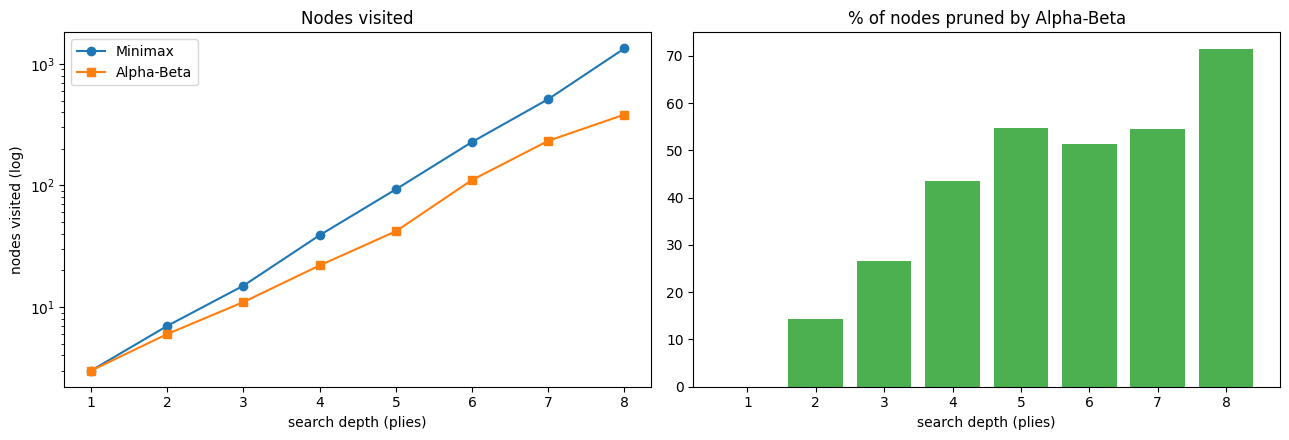

Moves played: [('A', (1, 0)), ('B', (3, 4)), ('A', (2, 0)), ('B', (3, 3)), ('A', (2, 1)), ('B', (3, 2)), ('A', (2, 2)), ('B', (4, 2)), ('A', (1, 2)), ('B', (4, 1)), ('A', (1, 3)), ('B', (4, 0)), ('A', (1, 4)), ('B', (3, 0)), ('A', (0, 4))]
Final score difference (A - B) = 4  -> our robot A wins | total nodes searched = 4294


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(adv_df["Depth"], adv_df["Minimax nodes"], "-o", label="Minimax"); ax[0].plot(adv_df["Depth"], adv_df["Alpha-Beta nodes"], "-s", label="Alpha-Beta")
ax[0].set_yscale("log"); ax[0].set_xlabel("search depth (plies)"); ax[0].set_ylabel("nodes visited (log)"); ax[0].set_title("Nodes visited"); ax[0].legend()
ax[1].bar(adv_df["Depth"], adv_df["Nodes saved %"], color="#4caf50"); ax[1].set_title("% of nodes pruned by Alpha-Beta"); ax[1].set_xlabel("search depth (plies)")
plt.tight_layout(); plt.show()

# --- play a complete game: our robot A (alpha-beta, depth 8) vs competitor B (alpha-beta, depth 3 - a shortsighted robot)
state, log, total_nodes = INIT, [], 0
for ply in range(40):
    if is_terminal(state): break
    depth = 8 if state[4] == 0 else 3
    mv, v, n = choose_move(state, depth, "alphabeta"); total_nodes += n
    state = next(ch for ch, m in moves(state) if m == mv)
    log.append(("A" if ply % 2 == 0 else "B", mv))
print("Moves played:", log)
print(f"Final score difference (A - B) = {state[3]}  ->", "our robot A wins" if state[3] > 0 else "robot B wins" if state[3] < 0 else "draw", f"| total nodes searched = {total_nodes}")

## Part 5 – Constraint Satisfaction Problems (Algorithms 16 – 20)
**Sub-problem – traffic-slot scheduling:** 14 robots must cross a shared choke-point (a lift/intersection). The day is cut into **4 time-slots (T1-T4)**.
* **Variables:** the 14 robots `R1 … R14`   * **Domains:** `{T1, T2, T3, T4}` (reduced for some robots, e.g. battery/charging restrictions)
* **Constraints:** two robots whose routes cross (an edge in the *conflict graph*) **must not** use the same slot.

This is a graph-colouring CSP. The instance is generated with a fixed seed so results are reproducible.

In [ ]:
def make_csp(seed=16, n=14, p=0.33):
    r = random.Random(seed)
    vs = [f"R{i}" for i in range(1, n + 1)]
    nb = {v: set() for v in vs}
    for a, b in itertools.combinations(vs, 2):
        if r.random() < p: nb[a].add(b); nb[b].add(a)
    dom = {v: ["T1", "T2", "T3", "T4"] for v in vs}
    for v in r.sample(vs, 5):                                       # unary constraints (a slot a robot cannot use)
        dom[v] = [s for s in dom[v] if s not in r.sample(["T1", "T2", "T3", "T4"], 1)]
    return vs, dom, nb

VARS, DOMAINS, NEIGH = make_csp()
print("Robots:", len(VARS), "| conflict edges:", sum(len(x) for x in NEIGH.values()) // 2)
print("Restricted domains:", {v: d for v, d in DOMAINS.items() if len(d) < 4})
print("Conflicts:", {v: sorted(n) for v, n in NEIGH.items()})

Robots: 14 | conflict edges: 35
Restricted domains: {'R1': ['T1', 'T3', 'T4'], 'R5': ['T2', 'T3', 'T4'], 'R12': ['T2', 'T3'], 'R13': ['T2', 'T3', 'T4']}
Conflicts: {'R1': ['R10', 'R11', 'R13', 'R8'], 'R2': ['R10', 'R13', 'R14', 'R3', 'R6'], 'R3': ['R11', 'R12', 'R2', 'R4', 'R5'], 'R4': ['R11', 'R14', 'R3', 'R7', 'R8', 'R9'], 'R5': ['R14', 'R3'], 'R6': ['R14', 'R2', 'R7', 'R8'], 'R7': ['R13', 'R14', 'R4', 'R6'], 'R8': ['R1', 'R10', 'R11', 'R14', 'R4', 'R6', 'R9'], 'R9': ['R13', 'R4', 'R8'], 'R10': ['R1', 'R11', 'R12', 'R13', 'R2', 'R8'], 'R11': ['R1', 'R10', 'R13', 'R14', 'R3', 'R4', 'R8'], 'R12': ['R10', 'R14', 'R3'], 'R13': ['R1', 'R10', 'R11', 'R2', 'R7', 'R9'], 'R14': ['R11', 'R12', 'R2', 'R4', 'R5', 'R6', 'R7', 'R8']}


In [ ]:
# CSP — Plain Backtracking Only

def solve_csp():
    stats = {
        "nodes": 0,
        "backtracks": 0,
        "checks": 0
    }

    def legal(v, value, assign):
        # Check value against already-assigned neighbours
        for n in NEIGH[v]:
            stats["checks"] += 1
            if assign.get(n) == value:
                return False
        return True

    def backtrack(assign):
        # Goal: all variables assigned
        if len(assign) == len(VARS):
            return dict(assign)

        # Plain/static variable ordering:
        # always select the first unassigned variable
        v = next(v for v in VARS if v not in assign)

        # Try values in the original domain order
        for x in DOMAINS[v]:
            stats["nodes"] += 1

            if legal(v, x, assign):
                assign[v] = x

                result = backtrack(assign)

                if result is not None:
                    return result

                # Undo assignment (backtrack)
                del assign[v]

        stats["backtracks"] += 1
        return None

    t0 = time.perf_counter()

    solution = backtrack({})

    stats["ms"] = (time.perf_counter() - t0) * 1000

    return solution, stats


def valid(sol):
    if sol is None:
        return False

    # Check unary/domain constraints
    if not all(sol[v] in DOMAINS[v] for v in VARS):
        return False

    # Check binary constraints
    for v in VARS:
        for n in NEIGH[v]:
            if sol[v] == sol[n]:
                return False

    return True


# Run plain backtracking
solution, stats = solve_csp()

print("\n--- Plain Backtracking CSP ---")
print("Solution:", solution)
print("Solved:", solution is not None)
print("Valid:", valid(solution))
print("Nodes (assignments):", stats["nodes"])
print("Backtracks:", stats["backtracks"])
print("Consistency checks:", stats["checks"])
print("Time (ms):", round(stats["ms"], 2))


--- Plain Backtracking CSP ---
Solution: {'R1': 'T1', 'R2': 'T2', 'R3': 'T1', 'R4': 'T3', 'R5': 'T2', 'R6': 'T3', 'R7': 'T2', 'R8': 'T4', 'R9': 'T1', 'R10': 'T3', 'R11': 'T2', 'R12': 'T2', 'R13': 'T4', 'R14': 'T1'}
Solved: True
Valid: True
Nodes (assignments): 9108
Backtracks: 2507
Consistency checks: 31777
Time (ms): 12.13


## Part 6 – Overall Comparison (Summary Table)

In [ ]:
summary = pd.DataFrame([
    ["Uninformed",  "BFS, UCS, DFS, DLS, IDDFS, Bidirectional", "Route S → G",             "Nodes expanded, memory, path cost"],
    ["Informed",    "Best-First, Greedy, A*",                   "Route S → G (heuristic)", "Nodes expanded, memory, path cost"],
    ["Local",       "Hill-Climbing, Genetic Algorithm",         "8-item pick order",       "Tour cost, gap to optimum, success rate"],
    ["Adversarial", "Minimax, Alpha-Beta",                      "2-robot item race",       "Nodes visited, same decision value"],
    ["CSP",         "backtrack",   "Traffic-slot scheduling", "Assignments, backtracks"],
], columns=["Family", "Algorithms", "Warehouse sub-problem", "Metrics used"])
display(summary)

best = nav_df.sort_values(["Path cost", "Nodes expanded"]).iloc[0]
print(f"Cheapest route cost = {opt}.  Optimal algorithms with the fewest nodes: ",
      nav_df[nav_df['Optimal?']].sort_values('Nodes expanded')[['Algorithm','Nodes expanded']].head(3).values.tolist())

,Family,Algorithms,Warehouse sub-problem,Metrics used
0,Uninformed,"BFS, UCS, DFS, DLS, IDDFS, Bidirectional",Route S → G,"Nodes expanded, memory, path cost"
1,Informed,"Best-First, Greedy, A*",Route S → G (heuristic),"Nodes expanded, memory, path cost"
2,Local,"Hill-Climbing, Genetic Algorithm",8-item pick order,"Tour cost, gap to optimum, success rate"
3,Adversarial,"Minimax, Alpha-Beta",2-robot item race,"Nodes visited, same decision value"
4,CSP,backtrack,Traffic-slot scheduling,"Assignments, backtracks"


Cheapest route cost = 22.  Optimal algorithms with the fewest nodes:  [['7. Best-First (0.5g+h)', 20], ['9. A*', 20], ['2. Uniform-Cost', 49]]


# [8] Results Analysis


### A. Uninformed and Informed search – route from dock S to packing station G
Warehouse fact: the shortest route has **18 steps**, but the direct aisles are congested, so the *cheapest* route costs **22** while the "shortest-in-steps" routes cost **62**.

| Algorithm | Steps | Cost | Nodes expanded | Peak memory | Optimal cost? |
|---|---|---|---|---|---|
| BFS | 18 | 62 | 62 | 6 | No |
| Uniform-Cost | 18 | **22** | 49 | 10 | **Yes** |
| DFS | 18 | 62 | 19 | 6 | No |
| Depth-Limited (l = 25) | 18 | 62 | 19 | 19 | No |
| IDDFS | 18 | 62 | 826 | 19 | No |
| Bidirectional | 18 | 62 | 53 | 12 | No |
| Best-First (0.5g + h) | 18 | **22** | 20 | 9 | **Yes** (by luck of w = 0.5) |
| Greedy Best-First | 18 | 62 | 19 | 6 | No |
| **A\*** | 18 | **22** | **20** | 9 | **Yes** |

**Observations**
* **BFS, IDDFS and Bidirectional** minimise the *number of steps* (18) but are blind to cell costs, so they walk through congested aisles (cost 62 – almost 3× the best). BFS/IDDFS/Bidirectional are only optimal when every step costs the same.
* **Uniform-Cost and A\*** are the only algorithms that guarantee the cheapest route. **A\* expanded 20 nodes against 49 for UCS** (≈ 59 % fewer) because the Manhattan heuristic focuses the search towards G, while UCS spreads in all directions.
* **DFS / DLS / Greedy** were the fastest (19 nodes) and used least memory but only because they were lucky – their answer (cost 62) is 2.8× worse than optimal. Their result depends on neighbour ordering and they give no optimality guarantee.
* **Depth-Limited Search** is incomplete when the limit is too small: with l = 10 and l = 15 it returned *cutoff* (the goal is at depth 18); l = 18 and l = 25 succeed.
* **IDDFS** paid the price of repeated work: 826 node expansions (≈ 13× BFS) in exchange for tiny memory (peak = depth ≈ 19 in the recursion stack, versus a frontier for BFS). In a grid where the frontier is small anyway, this trade-off is not worthwhile, but in huge/deep state spaces it is.
* **Bidirectional search** expanded 53 nodes vs 62 for BFS (≈ 15 % fewer) – the saving grows with larger maps because two radius-d/2 searches are much smaller than one radius-d search.
* **Best-First** (weighted, f = 0.5g + h) sits between UCS and Greedy: 20 nodes and, in this instance, optimal cost. With a weight < 1 on g the optimality guarantee is lost, so it should not be relied on in general.
* Memory values for DLS/IDDFS are the recursion depth (stack size); for the other algorithms they are the maximum frontier/priority-queue size.

### B. Local search – order of 8 picks (exact optimum by brute force = 82)
| Algorithm | Runs reaching optimum (30 runs) | Mean cost | Worst | Avg evaluations |
|---|---|---|---|---|
| Hill-Climbing (single run) | 14 / 30 | 84.6 (+3.2 %) | 96 | 141 |
| Hill-Climbing (10 random restarts) | **30 / 30** | 82.0 | 82 | 1 424 |
| Genetic Algorithm | 20 / 30 | 82.7 (+0.8 %) | 84 | 9 000 |
| Brute force | exact | 82 | – | 40 320 |

* A single **hill-climbing** run is extremely cheap (141 evaluations) but gets trapped in **local optima** almost half of the time (worst cost 96, 17 % above optimal).
* **Random restarts** fix this: 10 restarts found the optimum in every trial using only ~3.5 % of the evaluations of brute force.
* The **Genetic Algorithm** always ended within 2.4 % of the optimum (worst 84) and never got as bad as a single hill-climb, but it used many more evaluations than restart hill-climbing on this small problem. Its advantage appears on much larger instances (e.g. 30-50 picks) where brute force is impossible and swap-neighbourhood hill-climbing gets stuck more often.
* Both methods are **incomplete / non-optimal in theory**, yet give near-optimal answers in practice – for 8 picks brute force is still feasible (8! = 40 320) but for 20 picks it would need 2.4 × 10¹⁸ evaluations.

### C. Adversarial search – Minimax vs Alpha-Beta
| Depth | Minimax nodes | Alpha-Beta nodes | Nodes pruned |
|---|---|---|---|
| 4 | 39 | 22 | 43.6 % |
| 6 | 228 | 111 | 51.3 % |
| 8 | 1 341 | 383 | **71.4 %** |

* At every depth (1-8) both algorithms returned **exactly the same game value**, confirming that alpha-beta pruning does not change the decision.
* The pruning percentage **grows with depth** (0 % → 71 %), so alpha-beta can search deeper for the same time budget – the reason it is the standard algorithm for game playing.
* In the full-game simulation the robot searching to depth 8 beat the shortsighted robot searching only 3 plies (final score difference +4), showing the benefit of deeper look-ahead.

### D. Constraint satisfaction – 14 robots, 4 time-slots, 35 conflicts
Plain Backtracking successfully found a valid solution satisfying all constraints.
Variables were selected in a fixed order, with values tried sequentially.
When a conflict occurred, the algorithm backtracked and tried another value.

### E. Overall comparison
| Property | Best performer in this experiment |
|---|---|
| Fewest nodes among *optimal* route finders | **A\*** (20) vs UCS (49) |
| Lowest memory | DFS / Greedy (6) |
| Only ones that respected varying cell costs | UCS, A\* (and weighted best-first) |
| Best local search reliability | Hill-Climbing with restarts (30/30) |
| Greatest saving through pruning | Alpha-Beta (71 % at depth 8) |
| Greatest saving through heuristics | CSP (≈ 130-180×) |

# [9] Conclusion
* The Autonomous Amazon Warehouse Robot was successfully modelled as five different search problems – navigation, pick-route optimisation, competitive item collection, and traffic-slot scheduling – and **all 20 algorithms** were implemented and evaluated on the same warehouse.
* **Uninformed search:** BFS, IDDFS and Bidirectional search find the shortest path in *steps* but ignore congestion cost (cost 62 vs the best 22). **Uniform-Cost search** is the correct uninformed choice when costs differ. DFS is memory-cheap but not optimal, and Depth-Limited Search is incomplete when the limit is below the goal depth (limits 10 and 15 failed on an 18-step goal).
* **Informed search:** **A\*** with the admissible Manhattan heuristic gave the optimal cost (22) while expanding **59 % fewer nodes than UCS** – the best route planner for the robot. Greedy best-first is fast but can return poor routes (cost 62).
* **Local search:** Hill-climbing is very fast but is trapped by local optima (optimal in only 14/30 runs); **random restarts** or a **Genetic Algorithm** give near-optimal pick orders (within 0 – 2.4 % of the exact optimum), and scale to instances where exact search is impossible.
* **Adversarial search:** **Alpha-Beta pruning returns exactly the same decision as Minimax** while visiting up to **71 %** fewer nodes at depth 8, allowing deeper look-ahead and better play.
* **CSP:** Plain backtracking needed 2 521 assignments
* **Overall lesson:** no single algorithm is best everywhere – the choice depends on the problem: *A\** for weighted navigation, *local search* for large optimisation problems where only the final configuration matters, *alpha-beta* for adversarial decisions, and *heuristic-guided backtracking with inference* for constraint problems. Adding problem knowledge (heuristics, pruning, variable ordering) reduced the search effort by one to two orders of magnitude in every family.

*- Tushar Kalyanrao Kaldate*

